In [1]:
import torch
import torch.nn as nn
from d2l import torch as d2l

In [2]:
import math
import os
import random
import collections

In [3]:
d2l.DATA_HUB['ptb'] = (d2l.DATA_URL + 'ptb.zip',
'319d85e578af0cdc590547f26231e4e31cdf1e42')
data_dir='../data/ptb'
def load_ptb_data():
    with open(os.path.join(data_dir,'ptb.train.txt')) as f:
        txt=f.read()
    return [line.split() for line in txt.split('\n')]

sentences=load_ptb_data()
print(f"长度为：{len(sentences)}")

class Vocab:
    def __init__(self,tokens,min_freq=0,reserved_tokens=[]):
        if tokens and isinstance(tokens[0], list):
            tokens = [token for line in tokens for token in line]
    
        tokens_orgin=[token for line in tokens for token in line.split(' ')]
        self.idx_to_str=['<unk>']+reserved_tokens
        tokens_freq=collections.Counter(tokens_orgin)
        tokens_freq=sorted(tokens_freq.items(),key= lambda item:item[1],reverse=True)

        for token,freq in tokens_freq:
            if freq>=min_freq and token not in self.idx_to_str:
                self.idx_to_str.append(token)
        self.str_to_idx={name:idx for idx,name in enumerate(self.idx_to_str)}
        return
    def __getitem__(self,tokens):
        if not isinstance(tokens,(list,tuple)):
            return self.str_to_idx.get(tokens, self.unk)
        else:
            return [self.__getitem__(token) for token in tokens]

    def __len__(self):
        return len(self.idx_to_str)
    @property
    def unk(self):
        return self.str_to_idx['<unk>']


vocab=Vocab(sentences,10) 
sentence_test=['you','are','who','to','fight','with']
print(f"单一访问：{vocab['you']}\n, {vocab.idx_to_str[3]},\n 多访问{vocab[sentence_test]}")
print(len(vocab))


长度为：42069
单一访问：109
, of,
 多访问[109, 25, 55, 4, 1442, 21]
6719


'"the"的数量：之前=50770, 之后=2197'

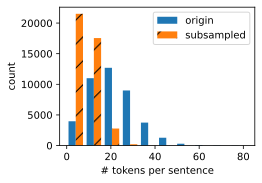

In [4]:
# 下采样：
def down_sample(sentences,vocab,t=1e-4):
    sentences = [[token for token in line if token is not vocab.unk] for line in sentences]
    sentences2 = [token for line in sentences for token in line]
    counter_freq=collections.Counter(sentences2)
    all_num=sum(counter_freq.values())
    def keep(token):
        return random.uniform(0,1)< (math.sqrt(t/counter_freq[token] * all_num))

    return ([[token for token in line if keep(token)] for line in sentences],counter_freq)

subsampled,_=down_sample(sentences,vocab)
d2l.show_list_len_pair_hist(
['origin', 'subsampled'], '# tokens per sentence',
'count', sentences, subsampled);

def compare_counts(token):
    return (f'"{token}"的数量：'
    f'之前={sum([l.count(token) for l in sentences])}, '
    f'之后={sum([l.count(token) for l in subsampled])}')
compare_counts('the')


In [5]:
corpus=[vocab[line] for line in subsampled]

corpus[:3]

[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [0, 2115, 0, 274, 406],
 [5277, 3054, 1580, 95]]

In [6]:
def get_center_and_context(corpus,max_window):
    center,context=[],[]

    for line in corpus:
        if len(line)<2:
            continue;
        center+=line
        window_size=random.randint(1,max_window)
        context+=[line[max(0,i-window_size):i]+line[i:min(len(line)-1,i+window_size)] for i in range(len(line))]

    return center,context


tiny_text=[list(range(7)),list(range(7,10))]
for center,context in zip(*get_center_and_context(tiny_text,2)):
    print(f'中心词：{center}, 上下文词：{context}')

中心词：0, 上下文词：[0, 1]
中心词：1, 上下文词：[0, 1, 2]
中心词：2, 上下文词：[0, 1, 2, 3]
中心词：3, 上下文词：[1, 2, 3, 4]
中心词：4, 上下文词：[2, 3, 4, 5]
中心词：5, 上下文词：[3, 4, 5]
中心词：6, 上下文词：[4, 5]
中心词：7, 上下文词：[7, 8]
中心词：8, 上下文词：[7, 8]
中心词：9, 上下文词：[7, 8]


In [7]:
all_centers,all_contexts=get_center_and_context(corpus,5)
print(sum([len(c) for c in all_contexts]))

1686790


In [ ]:
class randomGenerator:
    def __init__(self,sample_weights):
        self.sample_weights=sample_weights
        self.population=list(range(1,len(sample_weights)+1))
        self.candidate=[]
        self.i=0
        return
    def draw(self):
        if self.i>=len(self.candidate):
            self.candidate=random.choices(self.population,self.sample_weights,k=10000)
            self.i=0
        self.i+=1;
        return self.candidate[self.i-1]

def get_negatives(all_contexts,vocab,counter,negatives_num):
    sample_weight=[counter[i]**(0.75) for i in range(1,len(vocab))]
    all_negatives,generator=[],randomGenerator(sample_weight)
    for context in all_contexts:
        negatives=[]
        while(len(negatives)<len(context)*negatives_num):
            neg=generator.draw()
            if neg not in context:
                negatives.append(neg)
        all_negatives.append(negatives)
    return all_negatives

counter = collections.Counter([token for line in corpus for token in line])
all_negatives = get_negatives(all_contexts, vocab, counter, 5)



In [24]:
def batchify(data):
    max_len=max(len(c)+len(n) for _,c,n in data)
    centers,contexts_negatives,masks,labels=[],[],[],[]
    for center,context,negative in data:
        centers+=[center]
        cur_len=len(context)+len(negative)
        contexts_negatives+=[context+negative+[0]*(max_len-cur_len)]
        masks+=[[1]*(len(context)+len(negative))+[0]*(max_len-cur_len)]
        labels+=[[1]*len(context)+[0]*(max_len-len(context))]
    return (torch.tensor(centers),torch.tensor(contexts_negatives),torch.tensor(masks),torch.tensor(labels))

def load_data_ptb(batch_size, max_window_size, num_noise_words):
    num_workers = d2l.get_dataloader_workers() 
    sentences = load_ptb_data() 
    vocab = d2l.Vocab(sentences, min_freq=10) 
    subsampled, _ = down_sample(sentences, vocab) 
    corpus = [vocab[line] for line in subsampled] 
    counter = collections.Counter([token for line in corpus for token in line])
    all_centers, all_contexts = get_center_and_context(  corpus, max_window_size) 
    all_negatives = get_negatives(  all_contexts, vocab, counter, num_noise_words)

    class PTBDataSet(torch.utils.data.Dataset):
        def __init__(self,centers,contexts,negatives):
            super().__init__()
            self.centers=centers
            self.contexts=contexts
            self.negatives=negatives
            return
        def __getitem__(self,index):
            return (self.centers[index], self.contexts[index],  self.negatives[index])

        def __len__(self):
            return len(self.centers)

    ptbset=PTBDataSet(all_centers,all_contexts,all_negatives)
    data_iter=torch.utils.data.DataLoader(ptbset,batch_size,shuffle=True,collate_fn=batchify,num_workers=num_workers)
    return data_iter,vocab


In [25]:
data_iter, vocab = load_data_ptb(512, 5, 5) 
for batch in data_iter:
    for data in batch:
        print('shape:', data.shape) 
    break

shape: torch.Size([512])
shape: torch.Size([512, 60])
shape: torch.Size([512, 60])
shape: torch.Size([512, 60])
